# LSC5 | T9: SVM + TCN + Transformer con LOSO, espejo y ensamble por probabilidades OOF

Notebook de la tarea **T9** (`specs/tasks.md`, R5.1). Entrena **las tres arquitecturas** (SVM-RBF, TCN multistream y Transformer compacto) en una sola pasada y bajo las mismas reglas: LOSO anidado sobre los 3 participantes públicos, tres semillas y espejo (aumento + TTA). Guarda las probabilidades fuera de fold (OOF) de cada modelo y evalúa ensambles por *soft voting*.

## Qué cambia respecto a T7 (Transformer) y al TCN base

1. **Características de 436 dimensiones** (`USE_436 = True`): las 400 originales (sin cambios) + 36 nuevas por frame: 30 ángulos articulares de los dedos (3 por dedo y mano) y 6 distancias (muñeca de cada mano a la nariz, a la boca y al centro del torso). Con `USE_436 = False` se obtiene exactamente el pipeline de 400 características de T7, para hacer ablación.
2. **SVM con probabilidades honestas:** `CalibratedClassifierCV` (sigmoide) con calibración **entre firmantes** (entrenar con un firmante, calibrar con otro), sin ajustar nada con el participante reservado. Además usa TTA de espejo (en T7 el SVM no lo usaba), así que su accuracy puede diferir levemente de la de T7.
3. **Mismo protocolo para los tres modelos:** mismos folds, mismas semillas, mismo preprocesamiento. Cada modelo conserva sus propios hiperparámetros (`HPARAMS`).
4. **Ensamble con control de sobreajuste:** se evalúan cientos de combinaciones de pesos (rejilla de paso 0,05 = 231 combinaciones), pero la decisión final se toma con una regla explícita que compara contra el mejor modelo individual, contra el promedio uniforme y contra una **estimación con selección anidada** (los pesos de cada fold se eligen sin ver al participante reservado).
5. **Mapa de errores por firmante × vista × clase**, para comprobar si las características nuevas realmente corrigen la confusión `sign_04`/`sign_05` (en T7 el 82 % de los errores estaba en dos combinaciones firmante×vista).

## Reglas de integridad (cero fuga de datos)

- El test (M01) no se lee ni se inspecciona hasta que `RUN_FINAL_TEST_INFERENCE = True`.
- Escaladores y SVM se ajustan **solo** con el train de cada fold (incluye espejos). Las características nuevas son por muestra, sin estadísticas globales.
- La selección de épocas usa LOSO interno entre los 2 firmantes de entrenamiento del fold.
- Los pesos del ensamble se calculan solo con OOF de participantes públicos. El test nunca interviene.
- Lateralidad: M02 es zurdo y M03/M04 diestros. Espejo en entrenamiento y promedio muestra/espejo al predecir.

> **Advertencia sobre la búsqueda de pesos:** el OOF son 3 firmantes y 1125 muestras. Una diferencia de 0,5 puntos son ~6 muestras. Elegir la mejor combinación sobre esos mismos folds y reportar su accuracy es optimista. Por eso el reporte oficial del ensamble es la **estimación anidada**, no el máximo de la rejilla.

**Métrica principal:** Accuracy Top-1. También macro-F1, matrices de confusión y mapa de errores.

Fuentes de referencia: Manual LSC5 para estudiantes (octubre de 2026), Compromiso ético y uso responsable del dataset y página oficial del reto: https://www.latamiachallenge.com/dataset.php.

## 0. Configuración del experimento

En Kaggle agrega el dataset oficial con **Add Input** y activa GPU (*Settings → Accelerator*). Si la detección automática no encuentra las rutas, define `TRAIN_LANDMARKS_DIR`.

- `QUICK_TEST = True` hace una pasada de humo (1 semilla, 3 épocas) para comprobar que todo corre antes de lanzar la corrida completa.
- `RESUME = True` guarda el resultado de cada (modelo, semilla) en `/kaggle/working/lsc5_t9_artifacts/cache_*.pkl` y lo reutiliza si la celda se vuelve a ejecutar con la **misma configuración** (el nombre del caché incluye una huella de la configuración).
- Artefactos en `/kaggle/working/lsc5_t9_artifacts`.

In [2]:
from pathlib import Path
import os, re, json, math, random, time, copy, warnings, hashlib, pickle
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import torch
from torch import nn
from IPython.display import display
from torch.utils.data import Dataset, DataLoader

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kwargs): return x

# -----------------------------
# Configuración editable
# -----------------------------
DATA_ROOT = Path('/kaggle/input')
TRAIN_LANDMARKS_DIR = None  # Ejemplo: Path('/kaggle/input/lsc5/train/landmarks')
TEST_LANDMARKS_DIR = None   # Se usa únicamente en la celda opcional de inferencia final.

SEEDS = [42, 7, 123]
SEED = SEEDS[0]

# Protocolo común a los modelos de red
SEQ_LEN = 96
BATCH_SIZE = 32
MAX_EPOCHS = 80
PATIENCE = 15
NUM_WORKERS = 2
USE_AMP = True

# Hiperparámetros propios de cada arquitectura (los de T7 y los del TCN base)
HPARAMS = {
    'transformer': {'lr': 5e-4, 'wd': 1e-2, 'dropout': 0.3},
    'tcn':         {'lr': 1e-3, 'wd': 1e-3, 'dropout': 0.25},
}
D_MODEL, N_LAYERS, N_HEADS, FFN_DIM = 128, 2, 4, 256
HAND_DIM, BODY_DIM, FACE_DIM = 64, 32, 32
assert HAND_DIM + BODY_DIM + FACE_DIM == D_MODEL
TCN_CHANNELS = 96   # múltiplo de 3 (tres ramas)

# Características: True = 400 base + 36 nuevas (436); False = pipeline de T7 (400)
USE_436 = True

# Lateralidad (M02 zurdo; M03/M04 diestros)
MIRROR_AUG = True
MIRROR_TTA = True

# Ensamble
ENSEMBLE_STEP = 0.05        # rejilla del simplex: 231 combinaciones para 3 modelos
ENSEMBLE_MARGIN = 0.005     # ventaja mínima (accuracy) para preferir un ensamble sobre una opción más simple
FINAL_WEIGHTS_OVERRIDE = None   # p. ej. {'transformer': 0.5, 'tcn': 0.3, 'svm': 0.2}; None = regla automática

QUICK_TEST = False   # True: 1 semilla y 3 épocas (solo para comprobar que todo corre)
RESUME = True

# Debe permanecer False durante desarrollo/validación.
RUN_FINAL_TEST_INFERENCE = False

if QUICK_TEST:
    SEEDS, SEED, MAX_EPOCHS, PATIENCE, ENSEMBLE_STEP = [42], 42, 3, 3, 0.1

OUT_DIR = Path('/kaggle/working/lsc5_t9_artifacts')
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [f'sign_{i:02d}' for i in range(1, 6)]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
ID_TO_CLASS = {v: k for k, v in CLASS_TO_ID.items()}
MODEL_NAMES = ['svm', 'tcn', 'transformer']
NN_MODELS = ['tcn', 'transformer']

# Huella de la configuración: evita reutilizar cachés de otra configuración.
CFG_TAG = hashlib.md5(json.dumps({
    'seq': SEQ_LEN, 'bs': BATCH_SIZE, 'ep': MAX_EPOCHS, 'pat': PATIENCE, 'hp': HPARAMS,
    'd': [D_MODEL, N_LAYERS, N_HEADS, FFN_DIM, HAND_DIM, BODY_DIM, FACE_DIM, TCN_CHANNELS],
    'f436': USE_436, 'maug': MIRROR_AUG, 'ttta': MIRROR_TTA, 'quick': QUICK_TEST,
}, sort_keys=True).encode()).hexdigest()[:8]

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def seed_everything(seed=SEED):
    """Fija semillas para hacer los experimentos lo más reproducibles posible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
print('PyTorch:', torch.__version__, '| Dispositivo:', DEVICE)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No se detectó GPU. Activa GPU en Kaggle (Settings -> Accelerator).')
print('USE_436:', USE_436, '| Semillas:', SEEDS, '| SEQ_LEN:', SEQ_LEN, '| MAX_EPOCHS:', MAX_EPOCHS,
      '| PATIENCE:', PATIENCE, '| QUICK_TEST:', QUICK_TEST, '| CFG_TAG:', CFG_TAG)
print('Directorio de artefactos:', OUT_DIR)

PyTorch: 2.11.0+cu130 | Dispositivo: cuda
GPU: Tesla T4
USE_436: True | Semillas: [42, 7, 123] | SEQ_LEN: 96 | MAX_EPOCHS: 80 | PATIENCE: 15 | QUICK_TEST: False | CFG_TAG: be215e05
Directorio de artefactos: /kaggle/working/lsc5_t9_artifacts


## 1. Detección de rutas y construcción del inventario

El manual describe los archivos etiquetados en `train/landmarks/sign_XX/` y los nombres originales con el patrón `S##_M##_V##_C##_Clip####`. Extraemos el participante (`M##`) del nombre y usamos la carpeta `sign_XX` como etiqueta cuando esté disponible.

Para evitar que vistas simultáneas de una ejecución se separen en validación interna, creamos `group_id` usando la seña, el participante y `Clip####`, ignorando vista y cámara.

> Nota: en este dataset cada archivo tiene un `Clip` único, así que `group_id` es solo informativo. La validación interna **no** depende de él: usa LOSO interno entre firmantes (R1.2b).

In [3]:
def _class_dirs(path: Path):
    if not path.exists() or not path.is_dir():
        return []
    return [p for p in path.iterdir() if p.is_dir() and re.fullmatch(r'sign_\d{2}', p.name)]


def discover_train_landmarks(root=DATA_ROOT, override=None):
    """Encuentra train/landmarks sin entrar en carpetas de test."""
    if override is not None:
        p = Path(override)
        if not p.exists():
            raise FileNotFoundError(f'La ruta TRAIN_LANDMARKS_DIR no existe: {p}')
        return p

    if not root.exists():
        raise FileNotFoundError(f'No existe DATA_ROOT: {root}')

    candidates = []
    for p in root.rglob('landmarks'):
        if not p.is_dir():
            continue
        parts_lower = [part.lower() for part in p.parts]
        if 'test' in parts_lower:
            continue
        classes = _class_dirs(p)
        if len(classes) >= 5 and any(p.rglob('*.npy')):
            candidates.append(p)

    if not candidates:
        raise FileNotFoundError(
            'No encontré una carpeta train/landmarks con subcarpetas sign_01 ... sign_05. '
            'Define TRAIN_LANDMARKS_DIR manualmente.'
        )

    # Preferir una ruta que contenga explícitamente "train".
    candidates.sort(key=lambda p: ('train' not in [x.lower() for x in p.parts], len(str(p))))
    return candidates[0]


def parse_sample_metadata(path: Path):
    """Extrae etiqueta, participante, vista, cámara y grupo de ejecución."""
    stem = path.stem
    parent_match = re.fullmatch(r'(sign_\d{2})', path.parent.name)
    sign_match = re.search(r'(?:^|_)S(\d{2})(?:_|$)', stem)
    label = parent_match.group(1) if parent_match else (f'sign_{int(sign_match.group(1)):02d}' if sign_match else None)

    signer_match = re.search(r'(?:^|_)M(\d{2})(?:_|$)', stem)
    if signer_match is None:
        raise ValueError(f'No pude extraer participante M## del nombre: {path.name}')
    signer = f'M{signer_match.group(1)}'

    view_match = re.search(r'(?:^|_)V(\d{2})(?:_|$)', stem)
    camera_match = re.search(r'(?:^|_)C(\d{2})(?:_|$)', stem)
    clip_match = re.search(r'Clip(\d+)', stem, flags=re.IGNORECASE)

    if label not in CLASS_NAMES:
        raise ValueError(f'No pude identificar una clase sign_01 ... sign_05: {path}')

    # Agrupa las vistas/cámaras que comparten el mismo clip. Si no hay Clip, usa el archivo.
    group_id = f'{label}_{signer}_Clip{clip_match.group(1)}' if clip_match else stem
    return {
        'path': str(path),
        'video_id': stem,
        'label': label,
        'y': CLASS_TO_ID[label],
        'signer': signer,
        'view': f'V{view_match.group(1)}' if view_match else 'unknown',
        'camera': f'C{camera_match.group(1)}' if camera_match else 'unknown',
        'clip': clip_match.group(1) if clip_match else None,
        'group_id': group_id,
    }


TRAIN_LANDMARKS_DIR = discover_train_landmarks(DATA_ROOT, TRAIN_LANDMARKS_DIR)
records = []
for npy_path in sorted(TRAIN_LANDMARKS_DIR.rglob('*.npy')):
    # Esta carpeta debe ser exclusivamente el conjunto etiquetado de entrenamiento.
    records.append(parse_sample_metadata(npy_path))

metadata = pd.DataFrame(records)
# Integridad: ninguna ruta del inventario de entrenamiento puede pertenecer a una carpeta de test.
assert not any(part.lower() == 'test' for p in metadata['path'] for part in Path(p).parts), \
    'El inventario de entrenamiento contiene rutas de test.'
if metadata.empty:
    raise RuntimeError('No se encontraron archivos .npy en TRAIN_LANDMARKS_DIR.')

print('Carpeta de landmarks:', TRAIN_LANDMARKS_DIR)
print('Muestras etiquetadas:', len(metadata))
print('Participantes:', sorted(metadata.signer.unique()))
print('Clases:', sorted(metadata.label.unique()))
display(metadata.head())

Carpeta de landmarks: /kaggle/input/datasets/cristbalmagnata/lenguajeseas/train/train/landmarks
Muestras etiquetadas: 1125
Participantes: ['M02', 'M03', 'M04']
Clases: ['sign_01', 'sign_02', 'sign_03', 'sign_04', 'sign_05']


,path,video_id,label,y,signer,view,camera,clip,group_id
0,/kaggle/input/datasets/cristbalmagnata/lenguaj...,S01_M02_V01_C01_Clip076,sign_01,0,M02,V01,C01,076,sign_01_M02_Clip076
1,/kaggle/input/datasets/cristbalmagnata/lenguaj...,S01_M02_V01_C01_Clip077,sign_01,0,M02,V01,C01,077,sign_01_M02_Clip077
2,/kaggle/input/datasets/cristbalmagnata/lenguaj...,S01_M02_V01_C01_Clip078,sign_01,0,M02,V01,C01,078,sign_01_M02_Clip078
3,/kaggle/input/datasets/cristbalmagnata/lenguaj...,S01_M02_V01_C01_Clip079,sign_01,0,M02,V01,C01,079,sign_01_M02_Clip079
4,/kaggle/input/datasets/cristbalmagnata/lenguaj...,S01_M02_V01_C01_Clip080,sign_01,0,M02,V01,C01,080,sign_01_M02_Clip080


## 2. Auditoría del dataset

Antes de entrenar verificamos balance de clases, distribución por participante/vista, duplicados y correspondencia aproximada con los videos. No abrimos ni inspeccionamos el conjunto de test.

Muestras por clase:


,n
label,
sign_01,225
sign_02,225
sign_03,225
sign_04,225
sign_05,225


Muestras por participante y clase:


label,sign_01,sign_02,sign_03,sign_04,sign_05
signer,,,,,
M02,75,75,75,75,75
M03,75,75,75,75,75
M04,75,75,75,75,75


Muestras por vista:


,n
view,
V01,375
V02,375
V03,375


Grupos de ejecución únicos: 1125
Archivos repetidos por video_id: 0


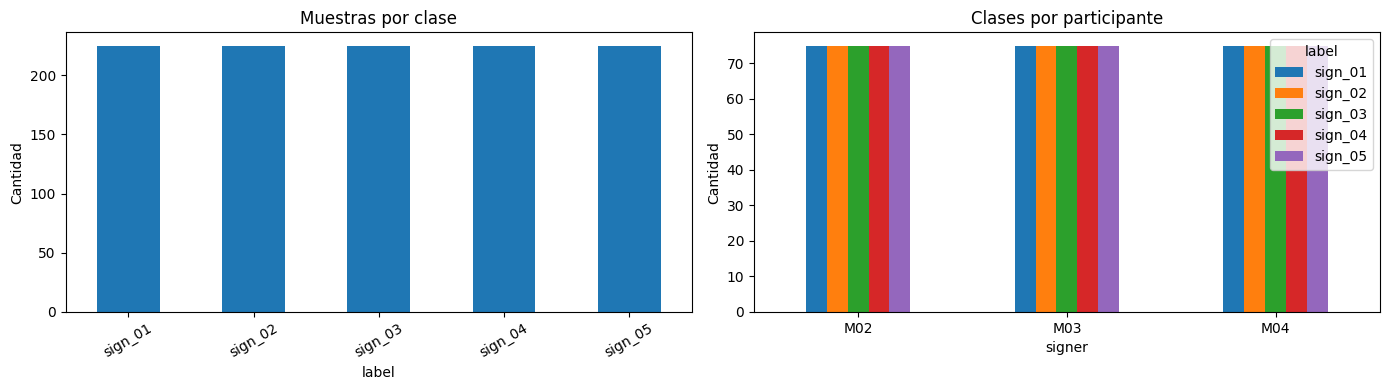

Landmarks con video correspondiente: 1125 / 1125


,label,file,shape,dtype,all_finite
0,sign_01,S01_M02_V01_C01_Clip076.npy,"(62, 1662)",float64,True
1,sign_01,S01_M02_V01_C01_Clip077.npy,"(83, 1662)",float64,True
2,sign_01,S01_M02_V01_C01_Clip078.npy,"(78, 1662)",float64,True
3,sign_02,S02_M02_V01_C02_Clip376.npy,"(69, 1662)",float64,True
4,sign_02,S02_M02_V01_C02_Clip377.npy,"(58, 1662)",float64,True
5,sign_02,S02_M02_V01_C02_Clip378.npy,"(77, 1662)",float64,True
6,sign_03,S03_M02_V01_C03_Clip676.npy,"(59, 1662)",float64,True
7,sign_03,S03_M02_V01_C03_Clip677.npy,"(72, 1662)",float64,True
8,sign_03,S03_M02_V01_C03_Clip678.npy,"(66, 1662)",float64,True
9,sign_04,S04_M02_V01_C04_Clip1000.npy,"(55, 1662)",float64,True


In [4]:
# Resumen de distribución
class_counts = metadata['label'].value_counts().reindex(CLASS_NAMES, fill_value=0)
signer_class = pd.crosstab(metadata['signer'], metadata['label']).reindex(columns=CLASS_NAMES, fill_value=0)
view_counts = metadata['view'].value_counts(dropna=False)

print('Muestras por clase:')
display(class_counts.rename('n').to_frame())
print('Muestras por participante y clase:')
display(signer_class)
print('Muestras por vista:')
display(view_counts.rename('n').to_frame())

# Conteos esperados según el Manual LSC5 para el split público de entrenamiento.
if len(metadata) != 1125:
    warnings.warn(f'Se esperaban 1125 landmarks públicos y se encontraron {len(metadata)}. Verifica la ruta.')
if metadata['signer'].nunique() > 3:
    raise ValueError('Se detectaron más de tres participantes en train. No incluyas el participante reservado para test.')
if not (signer_class == 75).all().all():
    warnings.warn('La distribución no coincide exactamente con 75 muestras por clase y participante; revisa el inventario.')
print('Grupos de ejecución únicos:', metadata['group_id'].nunique())
print('Archivos repetidos por video_id:', int(metadata['video_id'].duplicated().sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
class_counts.plot(kind='bar', ax=axes[0], title='Muestras por clase')
axes[0].set_ylabel('Cantidad'); axes[0].tick_params(axis='x', rotation=30)
signer_class.plot(kind='bar', ax=axes[1], title='Clases por participante')
axes[1].set_ylabel('Cantidad'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

# Comprobación de videos emparejados, si existe la carpeta hermana train/videos.
TRAIN_VIDEO_DIR = TRAIN_LANDMARKS_DIR.parent / 'videos'
if TRAIN_VIDEO_DIR.exists():
    video_stems = {p.stem for p in TRAIN_VIDEO_DIR.rglob('*.mp4')}
    metadata['has_video_pair'] = metadata['video_id'].isin(video_stems)
    print(f"Landmarks con video correspondiente: {metadata['has_video_pair'].sum()} / {len(metadata)}")
else:
    print('No encontré train/videos junto a train/landmarks; se continúa usando los .npy.')

# Inspección de forma y tipo en una muestra de archivos de cada clase.
shape_rows = []
for label in CLASS_NAMES:
    subset = metadata[metadata.label == label].head(3)
    for row in subset.itertuples():
        arr = np.load(row.path, allow_pickle=False)
        shape_rows.append({'label': label, 'file': Path(row.path).name,
                           'shape': arr.shape, 'dtype': str(arr.dtype),
                           'all_finite': bool(np.isfinite(arr).all())})
display(pd.DataFrame(shape_rows))

if metadata['signer'].nunique() != 3:
    warnings.warn(
        f"Se detectaron {metadata['signer'].nunique()} participantes etiquetados; "
        'el manual describe tres participantes públicos. Revisa que hayas agregado el split correcto.'
    )
if set(metadata['label'].unique()) != set(CLASS_NAMES):
    raise ValueError('Faltan clases. Revisa la ruta y la estructura del dataset.')

## 3. Ingeniería de características: 400 base (T7) + 36 nuevas

Se conservan **intactas** las 400 características de T7 (`landmarks_to_features`): manos relativas a la muñeca, trayectorias, cuerpo, rostro compacto, máscaras de presencia y velocidades. Con `USE_436 = True` se agregan 36 características estáticas por frame (sin velocidad), calculadas **solo desde el propio frame** (sin estadísticas del dataset):

| Bloque | Dim. | Contenido |
|---|---|---|
| Ángulos de dedos, mano izquierda | 15 | 3 ángulos articulares por dedo (pulgar: CMC, MCP, IP; resto: MCP, PIP, DIP), en radianes / π |
| Ángulos de dedos, mano derecha | 15 | ídem |
| Distancias, mano izquierda | 3 | muñeca → nariz, muñeca → boca (punto medio de los labios), muñeca → centro del torso; normalizadas por el ancho de hombros (mediana por video), solo en el plano x–y |
| Distancias, mano derecha | 3 | ídem |

Los ángulos y las distancias son invariantes a la reflexión, así que el espejo solo intercambia los bloques izquierdo/derecho; la celda 3c lo comprueba con `assert`. Todo valor de una mano ausente (o de rostro ausente) vale 0, igual que en las características base.

Las nuevas características entran en la **rama de manos** de ambos modelos de red.

In [5]:
# Índices de la representación descrita en el manual LSC5 / MediaPipe Holistic.
POSE_SLICE = slice(0, 132)
FACE_SLICE = slice(132, 1536)
LEFT_HAND_SLICE = slice(1536, 1599)
RIGHT_HAND_SLICE = slice(1599, 1662)

BODY_JOINTS = [11, 12, 13, 14, 15, 16, 23, 24]  # hombros, codos, muñecas y caderas
FACE_JOINTS = [1, 33, 133, 362, 263, 61, 291, 13, 14, 70, 300]
BASE_FEATURE_DIM = 200
FEATURE_DIM = BASE_FEATURE_DIM * 2  # posición + velocidad
MASK_FEATURES = [197, 198, 199, 397, 398, 399]


def load_landmark_array(path):
    """Carga un .npy y valida la forma esperada (T, 1662)."""
    arr = np.load(path, allow_pickle=False)
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim != 2:
        raise ValueError(f'{path}: esperaba matriz 2D, recibí {arr.shape}')
    if arr.shape[1] != 1662 and arr.shape[0] == 1662:
        arr = arr.T
    if arr.shape[1] != 1662:
        raise ValueError(f'{path}: esperaba 1662 características por frame, recibí {arr.shape}')
    arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)
    if len(arr) < 2:
        raise ValueError(f'{path}: secuencia demasiado corta ({len(arr)} frames)')
    return arr


def resample_frames(arr, target_len=SEQ_LEN):
    """Remuestreo lineal vectorizado a una longitud temporal fija."""
    n = len(arr)
    if n == target_len:
        return arr.astype(np.float32, copy=False)
    positions = np.linspace(0, n - 1, target_len, dtype=np.float32)
    lo = np.floor(positions).astype(np.int64)
    hi = np.minimum(lo + 1, n - 1)
    alpha = (positions - lo).astype(np.float32)[:, None]
    return (arr[lo] * (1.0 - alpha) + arr[hi] * alpha).astype(np.float32)


def landmarks_to_features(arr, target_len=SEQ_LEN):
    """Convierte landmarks crudos en una secuencia (target_len, 400)."""
    arr = resample_frames(arr, target_len)
    t = len(arr)

    pose = arr[:, POSE_SLICE].reshape(t, 33, 4)
    face = arr[:, FACE_SLICE].reshape(t, 468, 3)
    left_hand = arr[:, LEFT_HAND_SLICE].reshape(t, 21, 3)
    right_hand = arr[:, RIGHT_HAND_SLICE].reshape(t, 21, 3)

    # Centro del torso y escala robusta por video: distancia entre hombros.
    left_shoulder = pose[:, 11, :3]
    right_shoulder = pose[:, 12, :3]
    torso_center = (left_shoulder + right_shoulder) / 2.0
    shoulder_width = np.linalg.norm(left_shoulder[:, :2] - right_shoulder[:, :2], axis=1)
    valid_widths = shoulder_width[shoulder_width > 1e-4]
    body_scale = float(np.median(valid_widths)) if len(valid_widths) else 1.0
    body_scale = max(body_scale, 1e-3)

    def hand_features(hand):
        present = (np.max(np.abs(hand), axis=(1, 2)) > 1e-6).astype(np.float32)
        wrist = hand[:, 0, :]
        local = (hand - wrist[:, None, :]) / body_scale
        global_wrist = (wrist - torso_center) / body_scale
        local[present == 0] = 0.0
        global_wrist[present == 0] = 0.0
        return local.reshape(t, -1), global_wrist, present

    left_local, left_wrist, left_present = hand_features(left_hand)
    right_local, right_wrist, right_present = hand_features(right_hand)

    # Postura relativa al torso; se conserva visibilidad como cuarta característica.
    body_xyz = (pose[:, BODY_JOINTS, :3] - torso_center[:, None, :]) / body_scale
    body_visibility = pose[:, BODY_JOINTS, 3:4]
    body_features = np.concatenate([body_xyz, body_visibility], axis=2).reshape(t, -1)

    # Rasgos faciales compactos. Se conservan cambios locales respecto a la nariz.
    selected_face = face[:, FACE_JOINTS, :]
    nose = face[:, 1, :]
    eye_width = np.linalg.norm(face[:, 33, :2] - face[:, 263, :2], axis=1)
    valid_eye_widths = eye_width[eye_width > 1e-4]
    face_scale = float(np.median(valid_eye_widths)) if len(valid_eye_widths) else 1.0
    face_scale = max(face_scale, 1e-3)
    face_present = (np.max(np.abs(face), axis=(1, 2)) > 1e-6).astype(np.float32)
    face_local = (selected_face - nose[:, None, :]) / face_scale
    face_local[face_present == 0] = 0.0
    face_features = face_local.reshape(t, -1)

    # 126 mano + 6 trayectorias de muñeca + 32 cuerpo + 33 rostro + 3 máscaras = 200.
    base = np.concatenate([
        left_local, right_local,
        left_wrist, right_wrist,
        body_features, face_features,
        left_present[:, None], right_present[:, None], face_present[:, None]
    ], axis=1).astype(np.float32)

    if base.shape[1] != BASE_FEATURE_DIM:
        raise RuntimeError(f'Dimensión base inesperada: {base.shape[1]}')

    # Diferencias frame a frame. Las máscaras no representan velocidad.
    velocity = np.diff(base, axis=0, prepend=base[:1]).astype(np.float32)
    velocity[:, -3:] = 0.0
    features = np.concatenate([base, velocity], axis=1).astype(np.float32)
    if features.shape != (target_len, FEATURE_DIM):
        raise RuntimeError(f'Dimensión final inesperada: {features.shape}')
    return np.nan_to_num(features, nan=0.0, posinf=0.0, neginf=0.0)


print('Dimensión por frame:', FEATURE_DIM)
print('Máscaras de presencia:', MASK_FEATURES)

# Prueba rápida de procesamiento con un archivo real.
example_path = Path(metadata.iloc[0]['path'])
example_raw = load_landmark_array(example_path)
example_features = landmarks_to_features(example_raw)
print('Archivo de ejemplo:', example_path.name)
print('Forma original:', example_raw.shape)
print('Forma procesada:', example_features.shape)
print('Valores finitos:', np.isfinite(example_features).all())

Dimensión por frame: 400
Máscaras de presencia: [197, 198, 199, 397, 398, 399]
Archivo de ejemplo: S01_M02_V01_C01_Clip076.npy
Forma original: (62, 1662)
Forma procesada: (96, 400)
Valores finitos: True


In [6]:
# 3b. Espejo (lateralidad). Transformacion determinista aplicada a cada muestra por separado.
PAIRS = [(1,4),(2,5),(3,6),(7,8),(9,10),(11,12),(13,14),(15,16),(17,18),(19,20),(21,22),(23,24),(25,26),(27,28),(29,30),(31,32)]
FACE_PAIRS = [(33,263),(133,362),(61,291),(70,300)]  # solo los puntos de rostro que usa el modelo


def _flipx(block):
    """x -> 1-x solo donde el punto existe (los ceros significan 'no detectado')."""
    block = block.copy()
    present = np.abs(block).max(axis=2) > 1e-6
    block[..., 0] = np.where(present, 1.0 - block[..., 0], 0.0)
    return block


def mirror_raw(arr):
    t = len(arr)
    pose = _flipx(arr[:, POSE_SLICE].reshape(t, 33, 4))
    face = _flipx(arr[:, FACE_SLICE].reshape(t, 468, 3))
    lh = _flipx(arr[:, LEFT_HAND_SLICE].reshape(t, 21, 3))
    rh = _flipx(arr[:, RIGHT_HAND_SLICE].reshape(t, 21, 3))
    for i, j in PAIRS:
        pose[:, [i, j]] = pose[:, [j, i]]
    for i, j in FACE_PAIRS:
        face[:, [i, j]] = face[:, [j, i]]
    # al espejar, la mano izquierda pasa a ser la derecha y viceversa
    return np.concatenate([pose.reshape(t, -1), face.reshape(t, -1),
                           rh.reshape(t, -1), lh.reshape(t, -1)], axis=1).astype(np.float32)


_ex = load_landmark_array(example_path)
assert np.allclose(mirror_raw(mirror_raw(_ex)), _ex, atol=1e-5), 'espejar dos veces debe devolver el original'
print('Espejo OK (doble espejo = original).')

Espejo OK (doble espejo = original).


In [7]:
# 3c. Características nuevas (36): ángulos de dedos + distancias mano-rostro / mano-torso.
EXTRA_DIM = 36
INPUT_DIM = FEATURE_DIM + (EXTRA_DIM if USE_436 else 0)   # FEATURE_DIM = 400 (definido en 3)
FINGER_CHAINS = [(0, 1, 2, 3, 4), (0, 5, 6, 7, 8), (0, 9, 10, 11, 12), (0, 13, 14, 15, 16), (0, 17, 18, 19, 20)]


def _joint_angles(hand):
    """hand: (T, 21, 3) -> (T, 15): angulo en cada articulacion de cada dedo, dividido por pi."""
    out = []
    for chain in FINGER_CHAINS:
        for k in range(1, 4):
            p_prev, p_joint, p_next = hand[:, chain[k - 1]], hand[:, chain[k]], hand[:, chain[k + 1]]
            v1, v2 = p_prev - p_joint, p_next - p_joint
            denom = np.maximum(np.linalg.norm(v1, axis=1) * np.linalg.norm(v2, axis=1), 1e-6)
            cos = np.clip(np.sum(v1 * v2, axis=1) / denom, -1.0, 1.0)
            out.append(np.arccos(cos) / np.pi)
    return np.stack(out, axis=1)


def extra_features(arr):
    """arr: (T, 1662) crudo -> (T, 36). Orden: ang_izq(15), ang_der(15), dist_izq(3), dist_der(3)."""
    t = len(arr)
    pose = arr[:, POSE_SLICE].reshape(t, 33, 4)
    face = arr[:, FACE_SLICE].reshape(t, 468, 3)
    hands = [arr[:, LEFT_HAND_SLICE].reshape(t, 21, 3), arr[:, RIGHT_HAND_SLICE].reshape(t, 21, 3)]

    widths = np.linalg.norm(pose[:, 11, :2] - pose[:, 12, :2], axis=1)
    valid = widths[widths > 1e-4]
    scale = max(float(np.median(valid)) if len(valid) else 1.0, 1e-3)
    chest = pose[:, [11, 12, 23, 24], :2].mean(axis=1)            # centro del torso (hombros + caderas)
    face_present = np.max(np.abs(face), axis=(1, 2)) > 1e-6
    nose = face[:, 1, :2]
    mouth = (face[:, 13, :2] + face[:, 14, :2]) / 2.0

    blocks_ang, blocks_dist = [], []
    for hand in hands:
        present = np.max(np.abs(hand), axis=(1, 2)) > 1e-6
        ang = _joint_angles(hand)
        wrist = hand[:, 0, :2]
        dist = np.stack([np.linalg.norm(wrist - nose, axis=1),
                         np.linalg.norm(wrist - mouth, axis=1),
                         np.linalg.norm(wrist - chest, axis=1)], axis=1) / scale
        dist[~face_present, :2] = 0.0
        ang[~present] = 0.0
        dist[~present] = 0.0
        blocks_ang.append(ang)
        blocks_dist.append(dist)
    out = np.concatenate([blocks_ang[0], blocks_ang[1], blocks_dist[0], blocks_dist[1]], axis=1)
    return np.nan_to_num(out, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)


def full_features(raw, seq_len=SEQ_LEN):
    """Secuencia (seq_len, INPUT_DIM): 400 base (T7, sin cambios) [+ 36 nuevas si USE_436]."""
    arr = resample_frames(raw, seq_len)
    base = landmarks_to_features(arr, seq_len)     # el remuestreo ya está hecho: aquí no hace nada
    if not USE_436:
        return base
    return np.concatenate([base, extra_features(arr)], axis=1).astype(np.float32)


# Comprobaciones: el espejo solo intercambia izquierda/derecha en las características nuevas.
_e0, _e1 = extra_features(_ex), extra_features(mirror_raw(_ex))
assert _e0.shape == (len(_ex), EXTRA_DIM) and np.isfinite(_e0).all()
assert np.allclose(_e1[:, 0:15], _e0[:, 15:30], atol=1e-4) and np.allclose(_e1[:, 15:30], _e0[:, 0:15], atol=1e-4)
assert np.allclose(_e1[:, 30:33], _e0[:, 33:36], atol=1e-4) and np.allclose(_e1[:, 33:36], _e0[:, 30:33], atol=1e-4)
_f = full_features(_ex)
assert _f.shape == (SEQ_LEN, INPUT_DIM) and np.isfinite(_f).all()
assert np.allclose(_f[:, :FEATURE_DIM], landmarks_to_features(_ex, SEQ_LEN))   # las 400 base no cambian
print('Características nuevas OK | INPUT_DIM =', INPUT_DIM, '| forma de una muestra:', _f.shape)
print('Ángulos de dedos en [0,1]:', float(_e0[:, :30].min()) >= 0.0 and float(_e0[:, :30].max()) <= 1.0)

Características nuevas OK | INPUT_DIM = 436 | forma de una muestra: (96, 436)
Ángulos de dedos en [0,1]: True


## 4. Procesamiento del conjunto etiquetado

Se transforman los `.npy` del conjunto público de entrenamiento y sus versiones espejadas. No se guardan las características en disco (ocuparían cientos de MB y no son necesarias para la comparación).

In [8]:
def build_feature_tensor(meta_df, mirror=False, seq_len=SEQ_LEN):
    """Procesa las muestras etiquetadas (opcionalmente espejadas) y devuelve X."""
    sequences = []
    desc = 'Espejando landmarks' if mirror else 'Procesando landmarks'
    for row in tqdm(meta_df.itertuples(index=False), total=len(meta_df), desc=desc):
        raw = load_landmark_array(row.path)
        if mirror:
            raw = mirror_raw(raw)   # transformacion determinista por muestra
        sequences.append(full_features(raw, seq_len))
    return np.stack(sequences).astype(np.float32)

X = build_feature_tensor(metadata)
X_mirror = build_feature_tensor(metadata, mirror=True)
y = metadata['y'].to_numpy(dtype=np.int64)
signer_values_all = metadata['signer'].to_numpy()
SIGNERS = sorted(metadata['signer'].unique())
assert X.shape[2] == INPUT_DIM and X_mirror.shape == X.shape

print('X:', X.shape, X.dtype, '| X_mirror:', X_mirror.shape)
print('Uso aproximado de memoria (MB):', round((X.nbytes + X_mirror.nbytes) / 1024**2, 1))
print('Distribución de etiquetas:', Counter(y.tolist()))
metadata.to_csv(OUT_DIR / 'train_metadata.csv', index=False)

Procesando landmarks:   0%|          | 0/1125 [00:00<?, ?it/s]

Espejando landmarks:   0%|          | 0/1125 [00:00<?, ?it/s]

X: (1125, 96, 436) float32 | X_mirror: (1125, 96, 436)
Uso aproximado de memoria (MB): 359.3
Distribución de etiquetas: Counter({0: 225, 1: 225, 2: 225, 3: 225, 4: 225})


## 5. Utilidades de escalado y métricas

El escalador se ajusta exclusivamente sobre las secuencias que pertenecen al entrenamiento de cada partición.

In [9]:
def fit_sequence_scaler(X_train):
    """Ajusta media y desviación por característica usando solo X_train."""
    flat = X_train.reshape(-1, X_train.shape[-1]).astype(np.float64)
    mean = flat.mean(axis=0).astype(np.float32)
    std = flat.std(axis=0).astype(np.float32)
    std[std < 1e-5] = 1.0
    return {'mean': mean, 'std': std}


def apply_sequence_scaler(X_data, scaler):
    return ((X_data - scaler['mean'][None, None, :]) /
            scaler['std'][None, None, :]).astype(np.float32)


def calculate_metrics(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
    }


def print_confusion(y_true, y_pred, title='Matriz de confusión'):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap='Blues')
    ax.set_title(title)
    ax.set_xlabel('Predicción'); ax.set_ylabel('Etiqueta real')
    ax.set_xticks(range(5), CLASS_NAMES, rotation=35, ha='right')
    ax.set_yticks(range(5), CLASS_NAMES)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout(); plt.show()
    return cm

# Diagnóstico: la longitud temporal ya quedó homogeneizada.
print('Forma de X:', X.shape)
print('Rango global de características:', float(X.min()), 'a', float(X.max()))

Forma de X: (1125, 96, 436)
Rango global de características: -6.649068832397461 a 5.928998947143555


## 6. SVM-RBF con probabilidades calibradas entre firmantes

Mismo SVM que T7 (resumen temporal: media, desviación, cuantiles 10/90, primer y último frame), ahora con probabilidades para poder ensamblarlo. La calibración sigmoide usa `CalibratedClassifierCV` con validación cruzada **por firmante** (cada pliegue calibra con un firmante que el SVM de ese pliegue no vio) y `ensemble=False`, de modo que el clasificador final se entrena con todo el train del fold. Así las probabilidades reflejan el error entre personas y no el error dentro de un mismo firmante.

Para la predicción se promedia la probabilidad de la muestra y la de su espejo (`MIRROR_TTA`). Es una diferencia respecto al SVM de T7, que no usaba TTA.

In [10]:
def summarize_sequences(X_seq):
    """Resume cada secuencia sin perder por completo información de movimiento."""
    mean = X_seq.mean(axis=1)
    std = X_seq.std(axis=1)
    q10 = np.quantile(X_seq, 0.10, axis=1)
    q90 = np.quantile(X_seq, 0.90, axis=1)
    first = X_seq[:, 0, :]
    last = X_seq[:, -1, :]
    return np.concatenate([mean, std, q10, q90, first, last], axis=1).astype(np.float32)


def fit_svm(X_sum_train, y_train, groups_train):
    """SVM-RBF + calibracion sigmoide con CV por firmante (groups_train = firmante de cada fila)."""
    groups_train = np.asarray(groups_train)
    splits = [(np.where(groups_train != g)[0], np.where(groups_train == g)[0]) for g in sorted(set(groups_train))]
    svc = SVC(C=2.0, kernel='rbf', class_weight='balanced')
    try:
        calibrated = CalibratedClassifierCV(estimator=svc, method='sigmoid', cv=splits, ensemble=False)
    except TypeError:   # scikit-learn antiguo
        calibrated = CalibratedClassifierCV(base_estimator=svc, method='sigmoid', cv=splits, ensemble=False)
    model = Pipeline([('scale', StandardScaler()), ('calibrated_svc', calibrated)])
    model.fit(X_sum_train, y_train)
    return model


def svm_proba(model, X_raw, X_mir=None):
    p = model.predict_proba(summarize_sequences(X_raw))
    if MIRROR_TTA and X_mir is not None:
        p = (p + model.predict_proba(summarize_sequences(X_mir))) / 2.0
    return p


def run_loso_svm(X_seq, y_all, meta_df, X_mir, seed):
    """LOSO del SVM. El SVM es determinista; 'seed' solo se registra por uniformidad con las redes."""
    signer_values = meta_df['signer'].to_numpy()
    X_sum, X_mir_sum = summarize_sequences(X_seq), summarize_sequences(X_mir)
    rows = []
    oof_proba = np.full((len(y_all), len(CLASS_NAMES)), np.nan, dtype=np.float32)
    for heldout in sorted(set(signer_values)):
        tr = np.where(signer_values != heldout)[0]
        va = np.where(signer_values == heldout)[0]
        assert heldout not in set(signer_values[tr]), 'El firmante reservado aparece en train.'
        if MIRROR_AUG:
            Xf, yf, gf = (np.concatenate([X_sum[tr], X_mir_sum[tr]]), np.concatenate([y_all[tr], y_all[tr]]),
                          np.concatenate([signer_values[tr], signer_values[tr]]))
        else:
            Xf, yf, gf = X_sum[tr], y_all[tr], signer_values[tr]
        model = fit_svm(Xf, yf, gf)
        p = svm_proba(model, X_seq[va], X_mir[va])
        oof_proba[va] = p
        metrics = calculate_metrics(y_all[va], p.argmax(axis=1))
        rows.append({'model': 'svm', 'seed': seed, 'heldout_signer': heldout, 'n_train': len(tr),
                     'n_valid': len(va), 'best_epochs': np.nan, **metrics})
        print(f"  [svm] {heldout}: accuracy={metrics['accuracy']:.4f} | macro-F1={metrics['macro_f1']:.4f}")
    return rows, oof_proba, None

print('SVM definido.')

SVM definido.


## 7. Arquitecturas de red: TCN multistream y Transformer compacto

Ambas reciben `(batch, SEQ_LEN, INPUT_DIM)` y dividen cada frame en tres ramas anatómicas (manos, cuerpo, rostro). Con `USE_436 = True`, las 36 características nuevas se suman a la **rama de manos**.

- **TCN** (`LSC5_TCN`): idéntico al notebook base (codificadores 1×1 por rama, 4 bloques residuales dilatados, atención + máximo temporal).
- **Transformer** (`LSC5_Transformer`): idéntico a T7 (proyección por ramas a `D_MODEL` = 128, posición aprendible, encoder de 2 capas con `norm_first`, pooling por atención + promedio, clasificador lineal).

In [11]:
# Índices (orden de landmarks_to_features): manos 0:132, cuerpo 132:164, rostro 164:197, máscaras 197:200,
# velocidades +200. Las 36 características nuevas ocupan 400:436 y se asignan a la rama de manos.
HAND_STREAM_IDX = list(range(0, 132)) + list(range(200, 332)) + [197, 198] + (list(range(400, 436)) if USE_436 else [])
BODY_STREAM_IDX = list(range(132, 164)) + list(range(332, 364))
FACE_STREAM_IDX = list(range(164, 197)) + list(range(364, 397)) + [199]
_all_idx = HAND_STREAM_IDX + BODY_STREAM_IDX + FACE_STREAM_IDX
assert len(set(_all_idx)) == len(_all_idx) and max(_all_idx) < INPUT_DIM


class TemporalResidualBlock(nn.Module):
    def __init__(self, channels, dilation=1, dropout=0.25):
        super().__init__()
        padding = dilation
        self.block = nn.Sequential(
            nn.Conv1d(channels, channels, kernel_size=3, padding=padding, dilation=dilation),
            nn.BatchNorm1d(channels),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Conv1d(channels, channels, kernel_size=3, padding=padding, dilation=dilation),
            nn.BatchNorm1d(channels),
            nn.Dropout(dropout),
        )
        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.block(x))


class LSC5_TCN(nn.Module):
    """TCN multistream: codificadores separados y fusión temporal posterior."""
    def __init__(self, input_dim=INPUT_DIM, channels=TCN_CHANNELS, num_classes=5, dropout=0.25):
        super().__init__()
        if input_dim != INPUT_DIM:
            raise ValueError(f'input_dim debe ser {INPUT_DIM}, recibí {input_dim}')
        if channels % 3 != 0:
            raise ValueError('TCN_CHANNELS debe ser múltiplo de 3 para las tres ramas.')
        self.register_buffer('hand_idx', torch.tensor(HAND_STREAM_IDX, dtype=torch.long))
        self.register_buffer('body_idx', torch.tensor(BODY_STREAM_IDX, dtype=torch.long))
        self.register_buffer('face_idx', torch.tensor(FACE_STREAM_IDX, dtype=torch.long))
        branch_channels = channels // 3

        def stream_encoder(n_in):
            return nn.Sequential(nn.Conv1d(n_in, branch_channels, kernel_size=1),
                                 nn.BatchNorm1d(branch_channels), nn.GELU())

        self.hand_encoder = stream_encoder(len(HAND_STREAM_IDX))
        self.body_encoder = stream_encoder(len(BODY_STREAM_IDX))
        self.face_encoder = stream_encoder(len(FACE_STREAM_IDX))
        self.temporal = nn.Sequential(*[TemporalResidualBlock(channels, dilation=d, dropout=dropout)
                                        for d in [1, 2, 4, 8]])
        self.attention = nn.Conv1d(channels, 1, kernel_size=1)
        self.classifier = nn.Sequential(nn.Linear(channels * 2, 128), nn.GELU(),
                                        nn.Dropout(dropout), nn.Linear(128, num_classes))

    def forward(self, x):
        hand = x.index_select(2, self.hand_idx).transpose(1, 2)
        body = x.index_select(2, self.body_idx).transpose(1, 2)
        face = x.index_select(2, self.face_idx).transpose(1, 2)
        streams = torch.cat([self.hand_encoder(hand), self.body_encoder(body), self.face_encoder(face)], dim=1)
        features = self.temporal(streams)
        weights = torch.softmax(self.attention(features), dim=-1)
        attended = torch.sum(features * weights, dim=-1)
        maximum = torch.max(features, dim=-1).values
        return self.classifier(torch.cat([attended, maximum], dim=1))


def _branch(n_in, n_out):
    """Proyección de una rama anatómica: Linear -> LayerNorm -> GELU."""
    return nn.Sequential(nn.Linear(n_in, n_out), nn.LayerNorm(n_out), nn.GELU())


class LSC5_Transformer(nn.Module):
    """Transformer compacto: ramas anatómicas + posición aprendible + encoder + pooling temporal."""
    def __init__(self, input_dim=INPUT_DIM, seq_len=SEQ_LEN, d_model=D_MODEL, nhead=N_HEADS,
                 num_layers=N_LAYERS, dim_feedforward=FFN_DIM, dropout=0.3, num_classes=5):
        super().__init__()
        if input_dim != INPUT_DIM:
            raise ValueError(f'input_dim debe ser {INPUT_DIM}, recibí {input_dim}')
        self.register_buffer('hand_idx', torch.tensor(HAND_STREAM_IDX, dtype=torch.long))
        self.register_buffer('body_idx', torch.tensor(BODY_STREAM_IDX, dtype=torch.long))
        self.register_buffer('face_idx', torch.tensor(FACE_STREAM_IDX, dtype=torch.long))
        self.hand_proj = _branch(len(HAND_STREAM_IDX), HAND_DIM)
        self.body_proj = _branch(len(BODY_STREAM_IDX), BODY_DIM)
        self.face_proj = _branch(len(FACE_STREAM_IDX), FACE_DIM)
        self.fusion_norm = nn.LayerNorm(d_model)
        self.pos_embed = nn.Parameter(torch.zeros(1, seq_len, d_model))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        self.embed_dropout = nn.Dropout(dropout)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, activation='gelu', batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers,
                                             norm=nn.LayerNorm(d_model), enable_nested_tensor=False)
        self.attn_pool = nn.Linear(d_model, 1)
        self.classifier = nn.Sequential(nn.LayerNorm(d_model * 2), nn.Dropout(dropout),
                                        nn.Linear(d_model * 2, num_classes))

    def forward(self, x):
        if x.shape[1] != self.pos_embed.shape[1]:
            raise ValueError(f'Se esperaban {self.pos_embed.shape[1]} frames y llegaron {x.shape[1]}.')
        tokens = torch.cat([self.hand_proj(x.index_select(2, self.hand_idx)),
                            self.body_proj(x.index_select(2, self.body_idx)),
                            self.face_proj(x.index_select(2, self.face_idx))], dim=-1)
        tokens = self.embed_dropout(self.fusion_norm(tokens) + self.pos_embed)
        features = self.encoder(tokens)
        weights = torch.softmax(self.attn_pool(features), dim=1)
        attended = torch.sum(features * weights, dim=1)
        return self.classifier(torch.cat([attended, features.mean(dim=1)], dim=1))


def make_model(model_name):
    dropout = HPARAMS[model_name]['dropout']
    if model_name == 'tcn':
        return LSC5_TCN(dropout=dropout)
    if model_name == 'transformer':
        return LSC5_Transformer(dropout=dropout)
    raise ValueError(model_name)


# Prueba de forma y tamaño de ambos modelos.
for _name in NN_MODELS:
    _m = make_model(_name).to(DEVICE)
    with torch.no_grad():
        _out = _m(torch.zeros(2, SEQ_LEN, INPUT_DIM, device=DEVICE))
    print(f"{_name}: parámetros entrenables = {sum(p.numel() for p in _m.parameters() if p.requires_grad):,} | salida {tuple(_out.shape)}")
    del _m, _out
print('Dimensiones de ramas (manos, cuerpo, rostro):', len(HAND_STREAM_IDX), len(BODY_STREAM_IDX), len(FACE_STREAM_IDX))

tcn: parámetros entrenables = 263,078 | salida (2, 5)
transformer: parámetros entrenables = 303,590 | salida (2, 5)
Dimensiones de ramas (manos, cuerpo, rostro): 302 64 67


## 8. Entrenamiento, aumento de datos y selección interna de épocas

Mismo protocolo para las dos redes: aumento moderado (deformación temporal suave y ruido bajo) más espejo; AdamW con cosine annealing, *label smoothing* 0,03, recorte de gradiente y AMP; early stopping con `PATIENCE` sobre la accuracy de validación interna. El escalador se ajusta solo con el train de cada llamada. Cada red usa su `lr`, `weight_decay` y `dropout` de `HPARAMS`.

In [12]:
class SequenceDataset(Dataset):
    def __init__(self, X_data, y_data, augment=False):
        self.X = torch.from_numpy(np.asarray(X_data, dtype=np.float32))
        self.y = torch.from_numpy(np.asarray(y_data, dtype=np.int64))
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def _augment_sequence(self, x):
        # Deformación temporal monotónica suave.
        if random.random() < 0.65:
            t = x.shape[0]
            gamma = random.uniform(0.90, 1.10)
            positions = (np.linspace(0, 1, t, dtype=np.float32) ** gamma) * (t - 1)
            lo = np.floor(positions).astype(np.int64)
            hi = np.minimum(lo + 1, t - 1)
            alpha = (positions - lo)[:, None]
            x = x[lo] * (1.0 - alpha) + x[hi] * alpha
        # Ruido pequeño solo en variables continuas, no en máscaras binarias.
        if random.random() < 0.70:
            noise = np.random.normal(0, 0.012, size=x.shape).astype(np.float32)
            noise[:, MASK_FEATURES] = 0.0
            x = x + noise
        return x.astype(np.float32)

    def __getitem__(self, idx):
        x = self.X[idx].numpy().copy()
        if self.augment:
            x = self._augment_sequence(x)
        return torch.from_numpy(x), self.y[idx]


def make_loader(X_data, y_data, train=False):
    return DataLoader(SequenceDataset(X_data, y_data, augment=train), batch_size=BATCH_SIZE,
                      shuffle=train, num_workers=NUM_WORKERS,
                      pin_memory=(DEVICE.type == 'cuda'), drop_last=False)


def predict_model(model, X_scaled, batch_size=64):
    model.eval()
    outputs = []
    dummy_y = np.zeros(len(X_scaled), dtype=np.int64)
    loader = DataLoader(SequenceDataset(X_scaled, dummy_y, augment=False),
                        batch_size=batch_size, shuffle=False, num_workers=0)
    with torch.no_grad():
        for xb, _ in loader:
            logits = model(xb.to(DEVICE, non_blocking=True))
            outputs.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
    return np.concatenate(outputs, axis=0) if outputs else np.empty((0, 5), dtype=np.float32)


def predict_proba(model, scaler, X_raw, X_mir=None):
    """Probabilidades con escalador congelado; promedia con el espejo si MIRROR_TTA."""
    p = predict_model(model, apply_sequence_scaler(X_raw, scaler))
    if MIRROR_TTA and X_mir is not None:
        p = (p + predict_model(model, apply_sequence_scaler(X_mir, scaler))) / 2.0
    return p


def fit_model(model_name, X_train_raw, y_train, X_valid_raw=None, y_valid=None,
              max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED):
    """Ajusta scaler solo con train y entrena la red. Si hay validación, aplica early stopping."""
    hp = HPARAMS[model_name]
    seed_everything(seed)
    scaler = fit_sequence_scaler(X_train_raw)
    train_loader = make_loader(apply_sequence_scaler(X_train_raw, scaler), y_train, train=True)
    has_valid = X_valid_raw is not None and y_valid is not None
    if has_valid:
        valid_loader = make_loader(apply_sequence_scaler(X_valid_raw, scaler), y_valid, train=False)

    model = make_model(model_name).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=hp['lr'], weight_decay=hp['wd'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max_epochs)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.03)
    amp_enabled = bool(USE_AMP and DEVICE.type == 'cuda')
    try:
        grad_scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)
    except (AttributeError, TypeError):
        grad_scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

    best_epoch, best_accuracy, best_loss = max_epochs, -1.0, float('inf')
    best_state, epochs_without_improvement, history = None, 0, []

    for epoch in range(1, max_epochs + 1):
        model.train()
        running_loss, seen = 0.0, 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=amp_enabled):
                loss = criterion(model(xb), yb)
            grad_scaler.scale(loss).backward()
            grad_scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            grad_scaler.step(optimizer)
            grad_scaler.update()
            running_loss += float(loss.item()) * len(yb)
            seen += len(yb)
        row = {'epoch': epoch, 'train_loss': running_loss / max(seen, 1)}

        if has_valid:
            model.eval()
            val_loss_sum, val_seen, val_pred, val_true = 0.0, 0, [], []
            with torch.no_grad():
                for xb, yb in valid_loader:
                    xb = xb.to(DEVICE, non_blocking=True)
                    yb = yb.to(DEVICE, non_blocking=True)
                    with torch.autocast(device_type=DEVICE.type, enabled=amp_enabled):
                        logits = model(xb)
                        loss = criterion(logits, yb)
                    val_loss_sum += float(loss.item()) * len(yb)
                    val_seen += len(yb)
                    val_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
                    val_true.extend(yb.cpu().numpy().tolist())
            val_loss = val_loss_sum / max(val_seen, 1)
            val_acc = accuracy_score(val_true, val_pred)
            row.update({'val_loss': val_loss, 'val_accuracy': val_acc})
            improved = (val_acc > best_accuracy + 1e-6) or (abs(val_acc - best_accuracy) <= 1e-6 and val_loss < best_loss)
            if improved:
                best_accuracy, best_loss, best_epoch = float(val_acc), float(val_loss), epoch
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
        else:
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        history.append(row)
        scheduler.step()
        if has_valid and epochs_without_improvement >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, scaler, int(best_epoch), pd.DataFrame(history)

print('Funciones de entrenamiento definidas. AMP:', USE_AMP and DEVICE.type == 'cuda')

Funciones de entrenamiento definidas. AMP: True


## 9. Validación LOSO anidada de los tres modelos (multi-semilla)

Para cada modelo y cada semilla: un fold por participante reservado. En las redes, el LOSO interno entre los otros dos participantes decide el número de épocas; después se reentrena desde cero con los dos participantes completos (más espejos) y se evalúa **una sola vez** en el reservado. Las aserciones comprueban que el reservado nunca aparece en train. Se guardan las probabilidades OOF de cada (modelo, semilla).

Esta celda es la más larga. Con `RESUME = True`, si Kaggle se interrumpe, al relanzarla con la misma configuración reutiliza lo ya terminado.

In [13]:
def run_loso_nn(model_name, X_seq, y_all, meta_df, X_mir, seed):
    """LOSO anidado de una red para una semilla. Devuelve filas por fold, probabilidades OOF y épocas."""
    def with_mirror(idx):
        if MIRROR_AUG:
            return np.concatenate([X_seq[idx], X_mir[idx]]), np.concatenate([y_all[idx], y_all[idx]])
        return X_seq[idx], y_all[idx]

    signer_values = meta_df['signer'].to_numpy()
    signers = sorted(set(signer_values))
    fold_rows, best_epochs = [], []
    oof_proba = np.full((len(y_all), len(CLASS_NAMES)), np.nan, dtype=np.float32)

    for fold_no, heldout in enumerate(signers, start=1):
        t0 = time.time()
        print(f'\n[{model_name} | seed={seed}] FOLD {fold_no}/{len(signers)} | reservado: {heldout}')
        outer_train_idx = np.where(signer_values != heldout)[0]
        outer_valid_idx = np.where(signer_values == heldout)[0]
        assert heldout not in set(signer_values[outer_train_idx]), 'El firmante reservado aparece en train.'

        # LOSO interno: se entrena con un participante y se valida con el otro, en ambos sentidos.
        inner_epochs = []
        for s_val in sorted(set(signer_values[outer_train_idx])):
            itr = outer_train_idx[signer_values[outer_train_idx] != s_val]
            iva = outer_train_idx[signer_values[outer_train_idx] == s_val]
            assert not (set(signer_values[itr]) & set(signer_values[iva])), 'Fuga en LOSO interno.'
            Xi, yi = with_mirror(itr)
            _, _, be, _ = fit_model(model_name, Xi, yi, X_seq[iva], y_all[iva],
                                    max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=seed + fold_no)
            inner_epochs.append(be)
            print(f'  LOSO interno val={s_val}: mejor epoca {be}')
        best_epoch = max(1, int(round(float(np.mean(inner_epochs)))))
        best_epochs.append(best_epoch)
        print('  Epocas seleccionadas (media interna):', best_epoch)

        # Reentrenamiento desde cero con los dos participantes completos y evaluación única.
        Xo, yo = with_mirror(outer_train_idx)
        fold_model, fold_scaler, _, _ = fit_model(model_name, Xo, yo, None, None,
                                                  max_epochs=best_epoch, patience=best_epoch,
                                                  seed=seed + 100 + fold_no)
        probabilities = predict_proba(fold_model, fold_scaler, X_seq[outer_valid_idx], X_mir[outer_valid_idx])
        oof_proba[outer_valid_idx] = probabilities
        metrics = calculate_metrics(y_all[outer_valid_idx], probabilities.argmax(axis=1))
        fold_rows.append({'model': model_name, 'seed': seed, 'heldout_signer': heldout,
                          'n_train': len(outer_train_idx), 'n_valid': len(outer_valid_idx),
                          'best_epochs': best_epoch, **metrics})
        print(f"  [{model_name} | seed={seed}] {heldout}: accuracy={metrics['accuracy']:.4f} | "
              f"macro-F1={metrics['macro_f1']:.4f} | {time.time() - t0:.0f}s")
        del fold_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return fold_rows, oof_proba, best_epochs


def cache_path(model_name, seed):
    return OUT_DIR / f'cache_{model_name}_seed{seed}_{CFG_TAG}.pkl'


results_rows, oof_by_model, epochs_by_model = [], {m: {} for m in MODEL_NAMES}, {m: {} for m in NN_MODELS}
t_start = time.time()
for model_name in MODEL_NAMES:
    for s in SEEDS:
        cp = cache_path(model_name, s)
        if RESUME and cp.exists():
            with open(cp, 'rb') as f:
                rows_s, oof_s, epochs_s = pickle.load(f)
            print(f'[{model_name} | seed={s}] reutilizado desde caché ({cp.name})')
        else:
            print('\n' + '=' * 72 + f'\nMODELO {model_name.upper()} | SEMILLA {s}\n' + '=' * 72)
            if model_name == 'svm':
                rows_s, oof_s, epochs_s = run_loso_svm(X, y, metadata, X_mirror, seed=s)
            else:
                rows_s, oof_s, epochs_s = run_loso_nn(model_name, X, y, metadata, X_mirror, seed=s)
            with open(cp, 'wb') as f:
                pickle.dump((rows_s, oof_s, epochs_s), f)
        results_rows.extend(rows_s)
        oof_by_model[model_name][s] = oof_s
        if model_name in NN_MODELS:
            epochs_by_model[model_name][s] = epochs_s
print(f'\nTiempo total LOSO: {(time.time() - t_start) / 60:.1f} min')

all_results = pd.DataFrame(results_rows)
for m in MODEL_NAMES:
    assert not any(np.isnan(oof_by_model[m][s]).any() for s in SEEDS), f'OOF incompleto en {m}'
print('Resultados por modelo, semilla y fold:')
display(all_results[['model', 'seed', 'heldout_signer', 'best_epochs', 'accuracy', 'macro_f1']])


MODELO SVM | SEMILLA 42
  [svm] M02: accuracy=0.9200 | macro-F1=0.9202
  [svm] M03: accuracy=0.8747 | macro-F1=0.8778
  [svm] M04: accuracy=0.9147 | macro-F1=0.9125

MODELO SVM | SEMILLA 7
  [svm] M02: accuracy=0.9200 | macro-F1=0.9202
  [svm] M03: accuracy=0.8747 | macro-F1=0.8778
  [svm] M04: accuracy=0.9147 | macro-F1=0.9125

MODELO SVM | SEMILLA 123
  [svm] M02: accuracy=0.9200 | macro-F1=0.9202
  [svm] M03: accuracy=0.8747 | macro-F1=0.8778
  [svm] M04: accuracy=0.9147 | macro-F1=0.9125

MODELO TCN | SEMILLA 42

[tcn | seed=42] FOLD 1/3 | reservado: M02
  LOSO interno val=M03: mejor epoca 15
  LOSO interno val=M04: mejor epoca 10
  Epocas seleccionadas (media interna): 12
  [tcn | seed=42] M02: accuracy=0.9333 | macro-F1=0.9332 | 80s

[tcn | seed=42] FOLD 2/3 | reservado: M03
  LOSO interno val=M02: mejor epoca 21
  LOSO interno val=M04: mejor epoca 23
  Epocas seleccionadas (media interna): 22
  [tcn | seed=42] M03: accuracy=0.9173 | macro-F1=0.9116 | 108s

[tcn | seed=42] FOLD 

,model,seed,heldout_signer,best_epochs,accuracy,macro_f1
0,svm,42,M02,NaN,0.920000,0.920198
1,svm,42,M03,NaN,0.874667,0.877829
2,svm,42,M04,NaN,0.914667,0.912493
3,svm,7,M02,NaN,0.920000,0.920198
4,svm,7,M03,NaN,0.874667,0.877829
5,svm,7,M04,NaN,0.914667,0.912493
6,svm,123,M02,NaN,0.920000,0.920198
7,svm,123,M03,NaN,0.874667,0.877829
8,svm,123,M04,NaN,0.914667,0.912493
9,tcn,42,M02,12.0,0.933333,0.933216


## 10. Resumen por modelo

Para cada modelo: la media entre semillas (cada semilla es un LOSO completo) y el **ensamble de semillas** (promedio de las probabilidades OOF de las tres semillas). Se resalta el peor participante, porque el riesgo en test está en el firmante más difícil. Las probabilidades OOF promediadas por semilla (`P[modelo]`) son la entrada de la búsqueda de ensamble.

In [14]:
P = {m: np.mean([oof_by_model[m][s] for s in SEEDS], axis=0) for m in MODEL_NAMES}   # (N, 5) por modelo


def per_signer_scores(pred):
    accs = np.array([accuracy_score(y[signer_values_all == h], pred[signer_values_all == h]) for h in SIGNERS])
    f1s = np.array([f1_score(y[signer_values_all == h], pred[signer_values_all == h], average='macro', zero_division=0)
                    for h in SIGNERS])
    return accs, f1s


summary_rows = []
for m in MODEL_NAMES:
    df = all_results[all_results.model == m]
    seed_means = df.groupby('seed').accuracy.mean()
    accs, f1s = per_signer_scores(P[m].argmax(axis=1))
    summary_rows.append({'model': m,
                         'acc_mean_over_seeds': seed_means.mean(), 'acc_std_over_seeds': seed_means.std(ddof=0),
                         'acc_ens_mean': accs.mean(), 'acc_ens_std_folds': accs.std(ddof=0),
                         'acc_ens_worst_fold': accs.min(), 'f1_ens_mean': f1s.mean(),
                         **{f'acc_ens_{h}': a for h, a in zip(SIGNERS, accs)}})
model_summary = pd.DataFrame(summary_rows).sort_values('acc_ens_mean', ascending=False)
display(model_summary.round(4))

print('Accuracy por participante y semilla:')
display(all_results.pivot_table(index=['model', 'seed'], columns='heldout_signer', values='accuracy').round(4))

# Ablación frente a T7 (400 características). Solo comparable con los mismos hiperparámetros y semillas.
T7_REF = {  # medias por fold entre las 3 semillas de T7 (reports/resultados.md, sección 5)
    'transformer': {'M02': 0.9902222, 'M03': 0.9262222, 'M04': 0.9324444},
    'svm':         {'M02': 0.9226667, 'M03': 0.8746667, 'M04': 0.9120000},   # T7: sin TTA ni calibración
}
if USE_436 and not QUICK_TEST and SEQ_LEN == 96:
    rows = []
    for m in ['transformer', 'svm']:
        cur = all_results[all_results.model == m].groupby('heldout_signer').accuracy.mean()
        for h in SIGNERS:
            rows.append({'model': m, 'signer': h, 'T7_400': T7_REF[m][h], 'T9_436': cur[h], 'delta': cur[h] - T7_REF[m][h]})
    ab = pd.DataFrame(rows)
    ab_mean = ab.groupby('model')[['T7_400', 'T9_436', 'delta']].mean()
    print('Efecto de pasar de 400 a 436 características (T7 vs esta corrida):')
    display(ab.round(4)); display(ab_mean.round(4))
    print('Cambios de menos de ~0,01 en la media están dentro del ruido (3 participantes). '
          'El SVM además cambia por TTA y calibración, así que su delta no mide solo las características.')

,model,acc_mean_over_seeds,acc_std_over_seeds,acc_ens_mean,acc_ens_std_folds,acc_ens_worst_fold,f1_ens_mean,acc_ens_M02,acc_ens_M03,acc_ens_M04
2,transformer,0.9517,0.0036,0.9564,0.0281,0.9280,0.9563,0.9947,0.9280,0.9467
1,tcn,0.9093,0.0131,0.9111,0.0399,0.8560,0.9081,0.9493,0.9280,0.8560
0,svm,0.9031,0.0000,0.9031,0.0202,0.8747,0.9035,0.9200,0.8747,0.9147


Accuracy por participante y semilla:


heldout_signer       M02     M03     M04
model       seed                        
svm         7     0.9200  0.8747  0.9147
            42    0.9200  0.8747  0.9147
            123   0.9200  0.8747  0.9147
tcn         7     0.9387  0.9173  0.9173
            42    0.9333  0.9173  0.8827
            123   0.9547  0.9280  0.7947
transformer 7     0.9920  0.9307  0.9413
            42    0.9947  0.9093  0.9360
            123   0.9867  0.9280  0.9467

Efecto de pasar de 400 a 436 características (T7 vs esta corrida):


,model,signer,T7_400,T9_436,delta
0,transformer,M02,0.9902,0.9911,0.0009
1,transformer,M03,0.9262,0.9227,-0.0036
2,transformer,M04,0.9324,0.9413,0.0089
3,svm,M02,0.9227,0.9200,-0.0027
4,svm,M03,0.8747,0.8747,-0.0000
5,svm,M04,0.9120,0.9147,0.0027


,T7_400,T9_436,delta
model,,,
svm,0.9031,0.9031,-0.0000
transformer,0.9496,0.9517,0.0021


Cambios de menos de ~0,01 en la media están dentro del ruido (3 participantes). El SVM además cambia por TTA y calibración, así que su delta no mide solo las características.


## 11. Ensamble por *soft voting* sobre probabilidades OOF

`P_ens = w_svm·P_svm + w_tcn·P_tcn + w_transformer·P_transformer`, con pesos no negativos que suman 1. Se evalúa **toda la rejilla del simplex** (paso `ENSEMBLE_STEP`, 231 combinaciones con 0,05) y se reportan cuatro cosas:

1. **Referencias simples:** cada modelo solo y el promedio uniforme (1/3 cada uno).
2. **Mejor combinación de la rejilla** (optimista: se elige y se mide sobre los mismos folds).
3. **Estimación con selección anidada:** para cada participante reservado, los pesos se eligen usando *solo* los otros dos participantes y se miden en el reservado. Es una aproximación: el OOF de esos dos participantes proviene de modelos que sí vieron al reservado, así que queda un sesgo pequeño; aun así es mucho más honesta que (2).
4. **Meseta:** las combinaciones a menos de 0,002 del máximo; su promedio es una elección de pesos más estable que el óptimo puntual.

**Regla de decisión** (editable con `ENSEMBLE_MARGIN` o `FINAL_WEIGHTS_OVERRIDE`): se usa el ensamble ponderado solo si su estimación anidada supera al mejor modelo individual por al menos `ENSEMBLE_MARGIN`; si no, se usa el promedio uniforme si este ya supera al mejor individual por ese margen; si tampoco, se usa el mejor modelo individual.

Combinaciones evaluadas: 231
Top 10 de la rejilla (OPTIMISTA: elegido y medido sobre los mismos folds):


,w_svm,w_tcn,w_transformer,acc_mean,acc_worst,f1_mean,acc_M02,acc_M03,acc_M04
0,0.30,0.10,0.60,0.9609,0.9280,0.9606,1.0,0.9280,0.9547
1,0.35,0.05,0.60,0.9609,0.9280,0.9606,1.0,0.9280,0.9547
2,0.30,0.00,0.70,0.9600,0.9280,0.9598,1.0,0.9280,0.9520
3,0.35,0.10,0.55,0.9600,0.9280,0.9597,1.0,0.9280,0.9520
4,0.35,0.15,0.50,0.9600,0.9280,0.9596,1.0,0.9280,0.9520
5,0.25,0.05,0.70,0.9591,0.9280,0.9589,1.0,0.9280,0.9493
6,0.25,0.10,0.65,0.9591,0.9280,0.9589,1.0,0.9280,0.9493
7,0.30,0.05,0.65,0.9591,0.9280,0.9589,1.0,0.9280,0.9493
8,0.40,0.15,0.45,0.9591,0.9280,0.9587,1.0,0.9280,0.9493
9,0.40,0.00,0.60,0.9582,0.9147,0.9585,1.0,0.9147,0.9600



Modelos individuales (ensamble de semillas): {'svm': np.float64(0.9031), 'tcn': np.float64(0.9111), 'transformer': np.float64(0.9564)}
Promedio uniforme (pesos [0.3, 0.35, 0.35]): 0.9538

Selección anidada (pesos elegidos con los otros dos participantes):


,heldout_signer,w_svm,w_tcn,w_transformer,acc_on_heldout
0,M02,0.30,0.10,0.6,1.0000
1,M03,0.40,0.00,0.6,0.9147
2,M04,0.25,0.35,0.4,0.9333


Accuracy media con selección anidada: 0.9493
Mejor de la rejilla: 0.9609 | meseta: 9 combinaciones | pesos de meseta: [0.32, 0.08, 0.6]

DECISIÓN: modelo individual (transformer)
Pesos finales: {'svm': 0.0, 'tcn': 0.0, 'transformer': 1.0}
Accuracy OOF del ensamble final por participante: {'M02': np.float64(0.9947), 'M03': np.float64(0.928), 'M04': np.float64(0.9467)}
Media: 0.9564 | peor participante: 0.9280 | macro-F1 media: 0.9563
(Referencia honesta con selección anidada: 0.9493; mejor individual: 0.9564)
              precision    recall  f1-score   support

     sign_01       1.00      1.00      1.00       225
     sign_02       0.92      1.00      0.96       225
     sign_03       1.00      1.00      1.00       225
     sign_04       0.88      0.97      0.93       225
     sign_05       1.00      0.82      0.90       225

    accuracy                           0.96      1125
   macro avg       0.96      0.96      0.96      1125
weighted avg       0.96      0.96      0.96      112

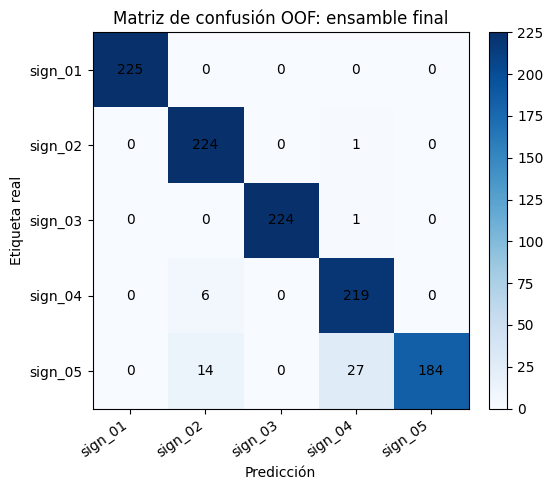

array([[225,   0,   0,   0,   0],
       [  0, 224,   0,   1,   0],
       [  0,   0, 224,   1,   0],
       [  0,   6,   0, 219,   0],
       [  0,  14,   0,  27, 184]])

In [15]:
def simplex_grid(n_models, step):
    k = int(round(1.0 / step))
    out = []
    def rec(prefix, left, slots):
        if slots == 1:
            out.append(prefix + [left]); return
        for i in range(left + 1):
            rec(prefix + [i], left - i, slots - 1)
    rec([], k, n_models)
    return np.array(out, dtype=np.float64) / k


GRID = simplex_grid(len(MODEL_NAMES), ENSEMBLE_STEP)          # (C, 3) pesos en el orden de MODEL_NAMES
P_stack = np.stack([P[m] for m in MODEL_NAMES])               # (3, N, 5)
masks = {h: signer_values_all == h for h in SIGNERS}

acc_grid = np.zeros((len(GRID), len(SIGNERS)))
f1_grid = np.zeros_like(acc_grid)
for ci, w in enumerate(GRID):
    pred = np.tensordot(w, P_stack, axes=(0, 0)).argmax(axis=1)
    for hi, h in enumerate(SIGNERS):
        acc_grid[ci, hi] = accuracy_score(y[masks[h]], pred[masks[h]])
        f1_grid[ci, hi] = f1_score(y[masks[h]], pred[masks[h]], average='macro', zero_division=0)

grid_df = pd.DataFrame(GRID, columns=[f'w_{m}' for m in MODEL_NAMES])
grid_df['acc_mean'] = acc_grid.mean(axis=1)
grid_df['acc_worst'] = acc_grid.min(axis=1)
grid_df['f1_mean'] = f1_grid.mean(axis=1)
for hi, h in enumerate(SIGNERS):
    grid_df[f'acc_{h}'] = acc_grid[:, hi]
grid_df = grid_df.sort_values(['acc_mean', 'f1_mean'], ascending=False).reset_index(drop=True)
print(f'Combinaciones evaluadas: {len(GRID)}')
print('Top 10 de la rejilla (OPTIMISTA: elegido y medido sobre los mismos folds):')
display(grid_df.head(10).round(4))

# 1) Referencias simples
equal_w = np.ones(len(MODEL_NAMES)) / len(MODEL_NAMES)
equal_idx = int(np.argmin(np.abs(GRID - equal_w).sum(axis=1)))     # combinación de la rejilla más cercana a 1/3 cada uno
equal_acc = acc_grid[equal_idx].mean()
single = {m: acc_grid[int(np.where((GRID == np.eye(len(MODEL_NAMES))[i]).all(axis=1))[0][0])].mean()
          for i, m in enumerate(MODEL_NAMES)}
best_single_name = max(single, key=single.get)
print('\nModelos individuales (ensamble de semillas):', {m: round(v, 4) for m, v in single.items()})
print(f'Promedio uniforme (pesos {GRID[equal_idx].round(3).tolist()}): {equal_acc:.4f}')

# 3) Selección anidada: pesos elegidos sin ver al reservado
dist_to_equal = np.abs(GRID - equal_w).sum(axis=1)
nested_rows, nested_choices = [], {}
for hi, h in enumerate(SIGNERS):
    others = [j for j in range(len(SIGNERS)) if j != hi]
    order = np.lexsort((dist_to_equal, -f1_grid[:, others].mean(axis=1), -acc_grid[:, others].mean(axis=1)))
    c = int(order[0])
    nested_choices[h] = GRID[c].tolist()
    nested_rows.append({'heldout_signer': h, **{f'w_{m}': GRID[c][i] for i, m in enumerate(MODEL_NAMES)},
                        'acc_on_heldout': acc_grid[c, hi]})
nested_df = pd.DataFrame(nested_rows)
nested_acc = float(nested_df.acc_on_heldout.mean())
print('\nSelección anidada (pesos elegidos con los otros dos participantes):')
display(nested_df.round(4))
print(f'Accuracy media con selección anidada: {nested_acc:.4f}')

# 4) Meseta y regla de decisión
grid_best = float(grid_df.acc_mean.iloc[0])
plateau = grid_df[grid_df.acc_mean >= grid_best - 0.002]
plateau_w = plateau[[f'w_{m}' for m in MODEL_NAMES]].mean().to_numpy()
plateau_w = np.round(plateau_w / plateau_w.sum(), 2)
plateau_w = plateau_w / plateau_w.sum()
print(f'Mejor de la rejilla: {grid_best:.4f} | meseta: {len(plateau)} combinaciones | pesos de meseta: {plateau_w.round(2).tolist()}')

if FINAL_WEIGHTS_OVERRIDE is not None:
    FINAL_WEIGHTS = {m: float(FINAL_WEIGHTS_OVERRIDE.get(m, 0.0)) for m in MODEL_NAMES}
    decision = 'manual (FINAL_WEIGHTS_OVERRIDE)'
elif nested_acc >= single[best_single_name] + ENSEMBLE_MARGIN:
    FINAL_WEIGHTS = {m: float(w) for m, w in zip(MODEL_NAMES, plateau_w)}
    decision = 'ensamble ponderado (pesos de meseta)'
elif equal_acc >= single[best_single_name] + ENSEMBLE_MARGIN:
    FINAL_WEIGHTS = {m: float(w) for m, w in zip(MODEL_NAMES, equal_w)}
    decision = 'promedio uniforme'
else:
    FINAL_WEIGHTS = {m: float(m == best_single_name) for m in MODEL_NAMES}
    decision = f'modelo individual ({best_single_name})'
_s = sum(FINAL_WEIGHTS.values()); FINAL_WEIGHTS = {m: w / _s for m, w in FINAL_WEIGHTS.items()}

p_final = sum(FINAL_WEIGHTS[m] * P[m] for m in MODEL_NAMES)
final_pred = p_final.argmax(axis=1)
final_accs, final_f1s = per_signer_scores(final_pred)
print('\n' + '=' * 72)
print('DECISIÓN:', decision)
print('Pesos finales:', {m: round(w, 3) for m, w in FINAL_WEIGHTS.items()})
print(f'Accuracy OOF del ensamble final por participante: {dict(zip(SIGNERS, final_accs.round(4)))}')
print(f'Media: {final_accs.mean():.4f} | peor participante: {final_accs.min():.4f} | macro-F1 media: {final_f1s.mean():.4f}')
print(f'(Referencia honesta con selección anidada: {nested_acc:.4f}; mejor individual: {single[best_single_name]:.4f})')
print(classification_report(y, final_pred, labels=list(range(5)), target_names=CLASS_NAMES, zero_division=0))
print_confusion(y, final_pred, 'Matriz de confusión OOF: ensamble final')

## 12. Mapa de errores por firmante × vista × clase

En T7, 45 de 55 errores eran clips de `sign_05` en solo dos combinaciones firmante×vista (M03/V01 y M04/V02), con hipótesis de que el detector encontraba las dos manos en casi todos los fotogramas. Aquí se repite el diagnóstico para cada modelo y para el ensamble final: si las características de 436 dimensiones (o el ensamble) corrigen el problema, esas dos celdas deben dejar de concentrar los errores.

In [16]:
view_values = metadata['view'].to_numpy()
true_names = np.array([ID_TO_CLASS[int(v)] for v in y])
preds_by_name = {m: P[m].argmax(axis=1) for m in MODEL_NAMES}
preds_by_name['ensemble'] = final_pred

print('REFERENCIA T7 (Transformer, 400 características): M03/V01 -> 25/25 errores y M04/V02 -> 20/25 en sign_05.\n')
error_map_frames = []
for name, pred in preds_by_name.items():
    err = pred != y
    df = pd.DataFrame({'signer': signer_values_all, 'view': view_values, 'true': true_names, 'err': err})
    sign5 = df[df.true == 'sign_05'].pivot_table(index='signer', columns='view', values='err', aggfunc='sum')
    total = df.pivot_table(index='signer', columns='view', values='err', aggfunc='sum')
    top2 = total.stack().sort_values(ascending=False).head(2)
    print(f'--- {name}: errores totales {int(err.sum())} de {len(y)} | recall sign_05 = '
          f'{((pred == 4) & (y == 4)).sum() / (y == 4).sum():.3f}')
    print('  errores de sign_05 por firmante x vista (25 clips por celda):')
    display(sign5)
    print(f'  las dos celdas con más errores concentran {int(top2.sum())} de {int(err.sum())} errores: '
          + ', '.join(f'{a}/{b}={int(v)}' for (a, b), v in top2.items()))
    error_map_frames.append(total.stack().rename(name))
error_map = pd.concat(error_map_frames, axis=1)
error_map.index.names = ['signer', 'view']
print('\nErrores totales por firmante x vista y modelo:')
display(error_map)

# Consistencia entre semillas del Transformer (en T7: 44 de 55 errores repetidos en las 3 semillas).
wrong = np.stack([oof_by_model['transformer'][s].argmax(axis=1) != y for s in SEEDS])
print('Transformer: muestras erróneas en 0/1/2/3 semillas:',
      [int((wrong.sum(axis=0) == k).sum()) for k in range(len(SEEDS) + 1)])

REFERENCIA T7 (Transformer, 400 características): M03/V01 -> 25/25 errores y M04/V02 -> 20/25 en sign_05.

--- svm: errores totales 109 de 1125 | recall sign_05 = 0.796
  errores de sign_05 por firmante x vista (25 clips por celda):


view,V01,V02,V03
signer,,,
M02,0,0,5
M03,0,15,0
M04,0,25,1


  las dos celdas con más errores concentran 75 de 109 errores: M03/V02=47, M04/V02=28
--- tcn: errores totales 100 de 1125 | recall sign_05 = 0.707
  errores de sign_05 por firmante x vista (25 clips por celda):


view,V01,V02,V03
signer,,,
M02,0,0,18
M03,25,2,0
M04,1,20,0


  las dos celdas con más errores concentran 57 de 100 errores: M04/V02=32, M03/V01=25
--- transformer: errores totales 49 de 1125 | recall sign_05 = 0.818
  errores de sign_05 por firmante x vista (25 clips por celda):


view,V01,V02,V03
signer,,,
M02,0,2,0
M03,25,0,0
M04,0,14,0


  las dos celdas con más errores concentran 39 de 49 errores: M03/V01=25, M04/V02=14
--- ensemble: errores totales 49 de 1125 | recall sign_05 = 0.818
  errores de sign_05 por firmante x vista (25 clips por celda):


view,V01,V02,V03
signer,,,
M02,0,2,0
M03,25,0,0
M04,0,14,0


  las dos celdas con más errores concentran 39 de 49 errores: M03/V01=25, M04/V02=14

Errores totales por firmante x vista y modelo:


svm  tcn  transformer  ensemble
signer view                                 
M02    V01     2    1            0         0
       V02     0    0            2         2
       V03    28   18            0         0
M03    V01     0   25           25        25
       V02    47    2            2         2
       V03     0    0            0         0
M04    V01     0   15            0         0
       V02    28   32           14        14
       V03     4    7            6         6

Transformer: muestras erróneas en 0/1/2/3 semillas: [1056, 19, 6, 44]


## 13. Guardado de resultados y probabilidades OOF

Todo queda en `/kaggle/working/lsc5_t9_artifacts`. Las probabilidades OOF (`oof_proba_*.npy`) son los insumos del ensamble y de cualquier análisis posterior.

In [17]:
all_results.to_csv(OUT_DIR / 'loso_all_models_results.csv', index=False)
model_summary.to_csv(OUT_DIR / 'model_summary.csv', index=False)
grid_df.to_csv(OUT_DIR / 'ensemble_grid_results.csv', index=False)
nested_df.to_csv(OUT_DIR / 'ensemble_nested_selection.csv', index=False)
error_map.to_csv(OUT_DIR / 'error_map_signer_view.csv')
for m in MODEL_NAMES:
    np.save(OUT_DIR / f'oof_proba_{m}.npy', P[m])                                              # (N, 5) promedio de semillas
    np.save(OUT_DIR / f'oof_proba_by_seed_{m}.npy', np.stack([oof_by_model[m][s] for s in SEEDS]))  # (n_seeds, N, 5)

oof_out = pd.DataFrame({'video_id': metadata['video_id'], 'signer': metadata['signer'], 'view': metadata['view'],
                        'true_sign': metadata['label']})
for m in MODEL_NAMES + ['ensemble']:
    oof_out[f'pred_{m}'] = [ID_TO_CLASS[int(v)] for v in preds_by_name[m]]
oof_out.to_csv(OUT_DIR / 'oof_predictions_all_models.csv', index=False)

with open(OUT_DIR / 'selected_epochs.json', 'w', encoding='utf-8') as f:
    json.dump({m: {str(s): [int(v) for v in epochs_by_model[m][s]] for s in SEEDS} for m in NN_MODELS} |
              {'folds_order': SIGNERS}, f, indent=2)

with open(OUT_DIR / 'ensemble_decision.json', 'w', encoding='utf-8') as f:
    json.dump({'decision': decision, 'weights': FINAL_WEIGHTS, 'model_order': MODEL_NAMES,
               'oof_accuracy_by_signer': dict(zip(SIGNERS, map(float, final_accs))),
               'oof_accuracy_mean': float(final_accs.mean()), 'oof_accuracy_worst': float(final_accs.min()),
               'oof_macro_f1_mean': float(final_f1s.mean()),
               'nested_selection_accuracy_mean': nested_acc, 'grid_best_accuracy_mean': grid_best,
               'equal_weights_accuracy_mean': float(equal_acc),
               'single_model_accuracy_mean': {m: float(v) for m, v in single.items()},
               'use_436': USE_436, 'seeds': SEEDS, 'seq_len': SEQ_LEN, 'cfg_tag': CFG_TAG,
               'hparams': HPARAMS, 'ensemble_step': ENSEMBLE_STEP, 'ensemble_margin': ENSEMBLE_MARGIN},
              f, indent=2, ensure_ascii=False)
print('Resultados guardados en:', OUT_DIR)

Resultados guardados en: /kaggle/working/lsc5_t9_artifacts


## 14. Entrenamiento final con los tres participantes públicos

Una vez congelados modelos y pesos del ensamble (sección 11), se entrena cada componente con **todos** los ejemplos etiquetados (más espejos):

- **Redes:** un modelo por semilla; las épocas son la mediana de las épocas seleccionadas por LOSO de **ese** modelo (todas las semillas y folds).
- **SVM:** un único modelo (determinista), con calibración entre los tres firmantes.

Los pesos se guardan en `.pt` (redes) y `.joblib` (SVM). Con ellos se puede hacer la inferencia final **sin reentrenar** (la GPU no es perfectamente determinista, así que reentrenar no reproduciría exactamente los modelos validados).

In [18]:
FINAL_EPOCHS = {m: max(1, int(np.median([e for s in SEEDS for e in epochs_by_model[m][s]]))) for m in NN_MODELS}
print('Épocas finales por modelo (mediana de LOSO):', FINAL_EPOCHS)

X_final, X_final_mirror = X, X_mirror
if MIRROR_AUG:
    X_train_final, y_train_final = np.concatenate([X, X_mirror]), np.concatenate([y, y])
    groups_final = np.concatenate([signer_values_all, signer_values_all])
else:
    X_train_final, y_train_final, groups_final = X, y, signer_values_all

final_nn = {m: [] for m in NN_MODELS}
for m in NN_MODELS:
    if FINAL_WEIGHTS[m] <= 0:
        print(f'{m}: peso 0 en el ensamble final, no se entrena.')
        continue
    for s in SEEDS:
        net, scaler_f, _, hist_f = fit_model(m, X_train_final, y_train_final, None, None,
                                             max_epochs=FINAL_EPOCHS[m], patience=FINAL_EPOCHS[m], seed=s + 999)
        final_nn[m].append((net, scaler_f))
        torch.save({'model_state_dict': net.state_dict(), 'scaler_mean': scaler_f['mean'], 'scaler_std': scaler_f['std'],
                    'config': {'model': m, 'seed': s, 'seq_len': SEQ_LEN, 'input_dim': INPUT_DIM, 'use_436': USE_436,
                               'hparams': HPARAMS[m], 'final_epochs': FINAL_EPOCHS[m], 'classes': CLASS_NAMES,
                               'mirror_aug': MIRROR_AUG, 'mirror_tta': MIRROR_TTA}},
                   OUT_DIR / f'lsc5_{m}_final_seed{s}.pt')
        hist_f.to_csv(OUT_DIR / f'final_training_history_{m}_seed{s}.csv', index=False)
        print(f'{m} (semilla {s}) guardado.')

final_svm = None
if FINAL_WEIGHTS['svm'] > 0:
    final_svm = fit_svm(summarize_sequences(X_train_final), y_train_final, groups_final)
    joblib.dump(final_svm, OUT_DIR / 'lsc5_svm_final.joblib', compress=3)
    print('SVM final guardado.')

with open(OUT_DIR / 'final_config.json', 'w', encoding='utf-8') as f:
    json.dump({'weights': FINAL_WEIGHTS, 'model_order': MODEL_NAMES, 'final_epochs': FINAL_EPOCHS, 'seeds': SEEDS,
               'use_436': USE_436, 'seq_len': SEQ_LEN, 'input_dim': INPUT_DIM, 'decision': decision,
               'mirror_aug': MIRROR_AUG, 'mirror_tta': MIRROR_TTA}, f, indent=2, ensure_ascii=False)
print('Artefactos disponibles:')
for p in sorted(OUT_DIR.iterdir()):
    if not p.name.startswith('cache_'):
        print('-', p.name, f'({p.stat().st_size / 1024**2:.2f} MB)')

Épocas finales por modelo (mediana de LOSO): {'tcn': 14, 'transformer': 25}
tcn: peso 0 en el ensamble final, no se entrena.
transformer (semilla 42) guardado.
transformer (semilla 7) guardado.
transformer (semilla 123) guardado.
Artefactos disponibles:
- ensemble_decision.json (0.00 MB)
- ensemble_grid_results.csv (0.02 MB)
- ensemble_nested_selection.csv (0.00 MB)
- error_map_signer_view.csv (0.00 MB)
- final_config.json (0.00 MB)
- final_training_history_transformer_seed123.csv (0.00 MB)
- final_training_history_transformer_seed42.csv (0.00 MB)
- final_training_history_transformer_seed7.csv (0.00 MB)
- loso_all_models_results.csv (0.00 MB)
- lsc5_transformer_final_seed123.pt (1.19 MB)
- lsc5_transformer_final_seed42.pt (1.19 MB)
- lsc5_transformer_final_seed7.pt (1.19 MB)
- model_summary.csv (0.00 MB)
- oof_predictions_all_models.csv (0.08 MB)
- oof_proba_by_seed_svm.npy (0.06 MB)
- oof_proba_by_seed_tcn.npy (0.06 MB)
- oof_proba_by_seed_transformer.npy (0.06 MB)
- oof_proba_svm.npy

## 15. Inferencia final sobre test (opcional y estrictamente separada)

**No ejecutar hasta congelar modelos y pesos.** Esta celda no calcula métricas, no adapta escaladores y no modifica ningún modelo: aplica la transformación determinista ya definida (con espejo), promedia las probabilidades de cada componente con los pesos finales y genera una predicción por ID.

Por defecto `RUN_FINAL_TEST_INFERENCE = False`: mientras esté en `False` no se lee ningún archivo de test.

In [19]:
def discover_test_landmarks(root=DATA_ROOT, override=None):
    if override is not None:
        p = Path(override)
        if not p.exists():
            raise FileNotFoundError(f'La ruta TEST_LANDMARKS_DIR no existe: {p}')
        return p
    candidates = []
    for p in root.rglob('landmarks'):
        if not p.is_dir():
            continue
        if 'test' in [part.lower() for part in p.parts] and any(p.rglob('*.npy')):
            candidates.append(p)
    if not candidates:
        raise FileNotFoundError('No encontré test/landmarks. Define TEST_LANDMARKS_DIR manualmente.')
    candidates.sort(key=lambda p: len(str(p)))
    return candidates[0]


def build_test_features(test_dir):
    paths = sorted(Path(test_dir).rglob('*.npy'))
    if not paths:
        raise RuntimeError(f'No hay .npy en {test_dir}')
    ids, feats, mfeats = [], [], []
    for p in tqdm(paths, desc='Inferencia: transformando test'):
        ids.append(p.stem)
        raw = load_landmark_array(p)
        feats.append(full_features(raw, SEQ_LEN))
        mfeats.append(full_features(mirror_raw(raw), SEQ_LEN))   # transformacion determinista por muestra
    return (pd.DataFrame({'video_id': ids, 'path': [str(p) for p in paths]}),
            np.stack(feats).astype(np.float32), np.stack(mfeats).astype(np.float32))


def predict_family(name, X_raw, X_mir):
    """Probabilidades de un componente del ensamble (redes: promedio de semillas; SVM: modelo único)."""
    if name == 'svm':
        return svm_proba(final_svm, X_raw, X_mir)
    return np.mean([predict_proba(net, sc, X_raw, X_mir) for net, sc in final_nn[name]], axis=0)


def predict_final_ensemble(X_raw, X_mir):
    return sum(FINAL_WEIGHTS[m] * predict_family(m, X_raw, X_mir) for m in MODEL_NAMES if FINAL_WEIGHTS[m] > 0)


def generate_submission(test_dir, out_dir=OUT_DIR):
    """Solo inferencia. No usa etiquetas ni estadísticas del conjunto de test."""
    test_meta, X_test, X_test_mirror = build_test_features(test_dir)
    probabilities = predict_final_ensemble(X_test, X_test_mirror)
    pred_ids = probabilities.argmax(axis=1)
    submission = pd.DataFrame({'video_id': test_meta['video_id'],
                               'predicted_sign': [ID_TO_CLASS[int(i)] for i in pred_ids]})

    templates = list(DATA_ROOT.rglob('submission_template.csv'))
    if templates:
        template = pd.read_csv(templates[0])
        if 'video_id' not in template.columns:
            raise ValueError('La plantilla no contiene columna video_id.')
        submission = template[['video_id']].merge(submission, on='video_id', how='left', validate='one_to_one')
        if submission['predicted_sign'].isna().any():
            raise ValueError('Hay IDs de plantilla sin predicción. Revisa los archivos de test.')

    if submission['video_id'].duplicated().any():
        raise ValueError('Hay video_id duplicados en la entrega.')
    if submission['predicted_sign'].isna().any():
        raise ValueError('Hay predicciones vacías.')
    if not set(submission['predicted_sign']).issubset(set(CLASS_NAMES)):
        raise ValueError('Se generó una etiqueta no permitida.')

    output_path = Path(out_dir) / 'submission.csv'
    submission.to_csv(output_path, index=False, encoding='utf-8')
    print('CSV generado:', output_path, '| Filas:', len(submission), '| Columnas:', submission.columns.tolist())
    display(submission.head())
    return submission


if RUN_FINAL_TEST_INFERENCE:
    TEST_LANDMARKS_DIR = discover_test_landmarks(DATA_ROOT, TEST_LANDMARKS_DIR)
    submission = generate_submission(TEST_LANDMARKS_DIR)
else:
    print('Inferencia de test desactivada. No se ha leído ningún archivo de test.')

Inferencia de test desactivada. No se ha leído ningún archivo de test.


In [21]:
import shutil
shutil.make_archive('/kaggle/working/resultados_transformer', 'zip', '/kaggle/working/lsc5_t9_artifacts')
print("ZIP listo para descargar")

ZIP listo para descargar


## 16. Checklist antes de entregar

- [ ] `train/landmarks` contiene únicamente los tres participantes públicos.
- [ ] Los tres folds LOSO reservaron un participante completo para cada modelo y cada semilla.
- [ ] El escalador y el SVM se ajustaron solo con el train de cada fold; las características nuevas no usan estadísticas globales.
- [ ] La selección de épocas usó LOSO interno (no un split aleatorio que filtre vistas).
- [ ] Se comparó 436 vs 400 características con la tabla de ablación (sección 10) antes de adoptar las nuevas.
- [ ] Se revisó el mapa de errores (sección 12): ¿dejaron M03/V01 y M04/V02 de concentrar los errores de `sign_05`?
- [ ] La decisión del ensamble se tomó con la regla de la sección 11 (estimación anidada), no con el máximo de la rejilla.
- [ ] Se congelaron modelos y pesos antes de ejecutar la inferencia final; la inferencia usa los pesos guardados, sin reentrenar.
- [ ] `RUN_FINAL_TEST_INFERENCE` permaneció en `False` durante todo el desarrollo.
- [ ] El CSV final tiene `video_id,predicted_sign`, sin índice, duplicados ni IDs faltantes.
- [ ] Se conservan el notebook, los pesos (`.pt`, `.joblib`), `ensemble_decision.json` y los OOF para auditoría.

**Importante:** los números finales salen de experimentos ejecutados; este notebook no promete ninguna accuracy específica. Con 3 participantes, diferencias de menos de ~1 punto están dentro del ruido.